# Paired HumanMethylation27 DMP analysis for GSE68319

This notebook processes the 20 HumanMethylation27 arrays in GEO series GSE68319: 10 normal-vein and 10 varicose-vein samples arranged as 10 patient-matched pairs. It imports the IDATs with minfi's 27K manifest support, performs GenomeStudio-like 27K preprocessing, records QC, and tests paired differential methylation with limma.


## Steps recorded here

1. Set up the R packages and confirm the WSL working directory.
2. Download the GSE68319 raw IDAT archive and GPL8490 HumanMethylation27 platform table.
3. Verify 20 complete Red/Green pairs and extract the 40 channel files.
4. Map GPL8490 bead addresses back to the 27,578 CpG IDs.
5. Match each IDAT pair to the GEO title, patient ID, and group.
6. Read all arrays with minfi, confirm the 27K platform and address coverage, and create normalized beta/M values plus detection-p QC.
7. Filter probes with poor detection in more than 5% of arrays.
8. Fit a paired limma model (patient blocking factor; Varicose versus Control) and report BH-adjusted DMP results and beta-value effect sizes.
9. Add 27K-specific hg19 probe and gene annotations; make a volcano plot and top-DMP beta heatmap.
10. Call DMRcate regions using the 27K coordinates and paired limma statistics.
11. Run GO Biological Process over-representation with a correction for the number of tested 27K CpGs assigned to each gene.

Important: ChAMP's released `champ.DMP` is documented for 450K/EPIC, so this notebook uses limma directly for a 27K-aware paired DMP test. The DMP analysis is exploratory (10 patient pairs) and should be validated independently.


## Step 0 — confirm the WSL home directory

In [1]:
getwd()
normalizePath(path.expand("~"), winslash = "/", mustWork = TRUE)

[1] "/home/surbhin"

[1] "/home/surbhin"

## Step 1 — configure and load the R packages

In [2]:
# Expose the Conda environment used by this R kernel so its toolchain is available.
r_home <- normalizePath(R.home(), winslash = "/", mustWork = TRUE)
conda_root <- dirname(dirname(r_home))
conda_bin <- file.path(conda_root, "bin")
if (dir.exists(conda_bin)) {
  Sys.setenv(PATH = paste(conda_bin, Sys.getenv("PATH"), sep = .Platform$path.sep))
}

# R 4.5 in this Conda environment uses C23 headers and Conda compiler wrappers.
# Point the wrappers at WSL's system sysroot so they can find installed native libraries.
cc <- file.path(conda_bin, "x86_64-conda-linux-gnu-cc")
cxx <- file.path(conda_bin, "x86_64-conda-linux-gnu-c++")
fc <- file.path(conda_bin, "x86_64-conda-linux-gnu-gfortran")
makevars <- NULL
if (file.exists(cc) && file.exists(cxx) && file.exists(fc)) {
  r_include <- file.path(r_home, "include")
  makevars <- file.path(tempdir(), "champ-Makevars")
  makevars_lines <- c(
    "CC = x86_64-conda-linux-gnu-cc -std=gnu23 --sysroot=/ -B/usr/lib/x86_64-linux-gnu/ -L/usr/lib/x86_64-linux-gnu",
    "CXX = x86_64-conda-linux-gnu-c++ -std=gnu++17 --sysroot=/ -B/usr/lib/x86_64-linux-gnu/ -L/usr/lib/x86_64-linux-gnu",
    "CXX11 = x86_64-conda-linux-gnu-c++ -std=gnu++11 --sysroot=/ -B/usr/lib/x86_64-linux-gnu/ -L/usr/lib/x86_64-linux-gnu",
    "CXX14 = x86_64-conda-linux-gnu-c++ -std=gnu++14 --sysroot=/ -B/usr/lib/x86_64-linux-gnu/ -L/usr/lib/x86_64-linux-gnu",
    "CXX17 = x86_64-conda-linux-gnu-c++ -std=gnu++17 --sysroot=/ -B/usr/lib/x86_64-linux-gnu/ -L/usr/lib/x86_64-linux-gnu",
    "F77 = x86_64-conda-linux-gnu-gfortran --sysroot=/ -B/usr/lib/x86_64-linux-gnu/ -L/usr/lib/x86_64-linux-gnu",
    "FC = x86_64-conda-linux-gnu-gfortran --sysroot=/ -B/usr/lib/x86_64-linux-gnu/ -L/usr/lib/x86_64-linux-gnu",
    paste0("CPPFLAGS += -I", r_include, " -I/usr/include/x86_64-linux-gnu -D_GNU_SOURCE"),
    paste0("CFLAGS += -D_GNU_SOURCE -I", r_include),
    "CXXFLAGS += -D_GNU_SOURCE"
  )
  writeLines(makevars_lines, makevars)
  Sys.setenv(R_MAKEVARS_USER = makevars)
}

if (!requireNamespace("BiocManager", quietly = TRUE)) {
  install.packages("BiocManager", repos = "https://cloud.r-project.org")
}
options(repos = BiocManager::repositories())

# Build HDF5 before applying the R-header workaround needed by some C dependencies.
if (!requireNamespace("Rhdf5lib", quietly = TRUE)) {
  BiocManager::install("Rhdf5lib", ask = FALSE, update = FALSE, Ncpus = 1)
}
if (!is.null(makevars)) {
  makevars_lines <- c(
    makevars_lines,
    paste0("CFLAGS += -include ", file.path(r_include, "R.h"))
  )
  writeLines(makevars_lines, makevars)
  Sys.setenv(R_MAKEVARS_USER = makevars)
}

# Bioconductor 3.22 methylumi imports lattice::parallel, removed in lattice 0.23.
if (!requireNamespace("methylumi", quietly = TRUE) &&
    !("parallel" %in% getNamespaceExports("lattice"))) {
  try(
    BiocManager::install("methylumi", ask = FALSE, update = FALSE, Ncpus = 1),
    silent = TRUE
  )
  if (!requireNamespace("methylumi", quietly = TRUE)) {
    methylumi_source <- tempfile(fileext = ".tar.gz")
    download.file(
      "https://bioconductor.org/packages/3.23/bioc/src/contrib/methylumi_2.58.1.tar.gz",
      methylumi_source,
      mode = "wb",
      method = "libcurl"
    )
    install.packages(methylumi_source, repos = NULL, type = "source", dependencies = FALSE)
  }
}

required_packages <- c("GEOquery", "ChAMP", "minfi", "illuminaio", "IlluminaHumanMethylation27kmanifest", "IlluminaHumanMethylation27kanno.ilmn12.hg19", "DMRcate", "goseq", "org.Hs.eg.db", "AnnotationDbi", "GO.db", "GenomicRanges", "IRanges", "ggplot2", "R.utils")
missing_packages <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(missing_packages)) {
  BiocManager::install(missing_packages, ask = FALSE, update = FALSE, Ncpus = 1)
}

still_missing <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(still_missing)) {
  stop("These packages did not install: ", paste(still_missing, collapse = ", "))
}


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org



Setting options('download.file.method.GEOquery'='auto')



Setting options('GEOquery.inmemory.gpl'=FALSE)



No methods found in package ‘RSQLite’ for request: ‘dbListFields’ when loading ‘lumi’



Warning message:
“replacing previous import ‘plyr::mutate’ by ‘plotly::mutate’ when loading ‘ChAMP’”


Warning message:
“replacing previous import ‘plyr::rename’ by ‘plotly::rename’ when loading ‘ChAMP’”


... (4 outputs left out)

Warning message:
"replacing previous import 'plyr::is.discrete' by 'Hmisc::is.discrete' when loading 'ChAMP'"


Warning message:
"replacing previous import 'plotly::last_plot' by 'ggplot2::last_plot' when loading 'ChAMP'"


Warning message:
"replacing previous import 'globaltest::model.matrix' by 'stats::model.matrix' when loading 'ChAMP'"


Warning message:
"replacing previous import 'globaltest::p.adjust' by 'stats::p.adjust' when loading 'ChAMP'"


In [3]:
suppressPackageStartupMessages({
  library(GEOquery)
  library(Biobase)
  library(ChAMP)
  library(minfi)
})
# ChAMP 2.40 passes mc.cores, which the current DMRcate API no longer accepts.
# Consume that legacy argument in ChAMP only; DMRcate uses its default core behavior.
if (!"mc.cores" %in% names(formals(DMRcate::dmrcate))) {
  champ_imports <- parent.env(asNamespace("ChAMP"))
  if (exists("dmrcate", envir = champ_imports, inherits = FALSE)) {
    champ_dmrcate_compat <- local({
      dmrcate_impl <- DMRcate::dmrcate
      function(object, ..., mc.cores = NULL) dmrcate_impl(object, ...)
    })
    unlockBinding("dmrcate", champ_imports)
    assign("dmrcate", champ_dmrcate_compat, envir = champ_imports)
    lockBinding("dmrcate", champ_imports)
  }
}


## Step 2 — download the raw archive and GPL8490 platform table

The GEO archive is about 19.5 MB and contains the 20 sample Red/Green IDAT pairs. The machine-readable GPL8490 table provides the explicit mapping from IDAT bead addresses to CpG IDs. minfi's installed `IlluminaHumanMethylation27kmanifest` package supplies the platform manifest for signal processing.

Illumina's Product Support Files page lists the content list; its v1.2 BPM processing manifest is on the separate [HumanMethylation27 Product Files page](https://support.illumina.com/downloads/humanmethylation27_product_files.html). This notebook uses the GPL8490 table and Bioconductor manifest package for the calculations rather than parsing BPM.


In [4]:
geo_id <- "GSE68319"
work_dir <- file.path(path.expand("~"), geo_id)
idat_dir <- file.path(work_dir, "raw")
dir.create(idat_dir, recursive = TRUE, showWarnings = FALSE)

raw_archive <- file.path(work_dir, paste0(geo_id, "_RAW.tar"))
platform_manifest_file <- file.path(
  work_dir, "GPL8490_HumanMethylation27_270596_v.1.2.csv.gz"
)
geo_series_url <- "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE68nnn/GSE68319/suppl"
geo_platform_url <- "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL8nnn/GPL8490/suppl"

download_if_missing <- function(url, destfile) {
  if (!file.exists(destfile) || is.na(file.info(destfile)$size) || file.info(destfile)$size == 0) {
    download.file(url, destfile = destfile, mode = "wb", method = "libcurl", quiet = FALSE)
  }
  stopifnot(file.exists(destfile), file.info(destfile)$size > 0)
  normalizePath(destfile, winslash = "/", mustWork = TRUE)
}

download_if_missing(file.path(geo_series_url, paste0(geo_id, "_RAW.tar")), raw_archive)
download_if_missing(file.path(geo_platform_url, basename(platform_manifest_file)), platform_manifest_file)
file.info(c(raw_archive, platform_manifest_file))[, c("size", "mtime"), drop = FALSE]


[1] "/home/surbhin/GSE68319/GSE68319_RAW.tar"

[1] "/home/surbhin/GSE68319/GPL8490_HumanMethylation27_270596_v.1.2.csv.gz"

,size,mtime
,<dbl>,<dttm>
/home/surbhin/GSE68319/GSE68319_RAW.tar,20408320,2026-11-12 13:06:57
/home/surbhin/GSE68319/GPL8490_HumanMethylation27_270596_v.1.2.csv.gz,6020044,2026-11-12 13:14:50


## Step 3 — verify the IDAT pairs and extract the cohort

Each array needs exactly one Red and one Green channel file. The checks below verify that the archive has 40 IDAT files, 20 distinct sample basenames, and no missing or duplicated channel before importing.


In [5]:
archive_entries <- utils::untar(raw_archive, list = TRUE)
idat_entries <- grep("\\.idat\\.gz$", archive_entries, value = TRUE, ignore.case = TRUE)
if (length(idat_entries) != 40L) stop("Expected 40 compressed IDAT channel files (20 arrays x 2 colors).")

file_names <- basename(idat_entries)
channel <- tolower(sub("^.*_(Red|Grn)\\.idat\\.gz$", "\\1", file_names, ignore.case = TRUE))
array_stems <- sub("_(Red|Grn)\\.idat\\.gz$", "", file_names, ignore.case = TRUE)
if (any(!channel %in% c("red", "grn"))) stop("Unexpected IDAT channel filename.")
pair_counts <- table(
  factor(array_stems, levels = unique(array_stems)),
  factor(channel, levels = c("red", "grn"))
)
if (any(pair_counts != 1L)) stop("Each array must have exactly one Red and one Green IDAT.")
pair_stems <- rownames(pair_counts)
pair_gsm <- sub("_.*$", "", pair_stems)
if (length(pair_stems) != 20L || length(unique(pair_gsm)) != 20L) {
  stop("Expected exactly 20 distinct GEO samples.")
}

# Extract the 40 compressed files while keeping the original tar archive.
if (length(list.files(idat_dir, pattern = "\\.idat\\.gz$", recursive = TRUE)) != 40L) {
  utils::untar(raw_archive, exdir = idat_dir)
}
idat_gz_files <- list.files(idat_dir, pattern = "\\.idat\\.gz$", full.names = TRUE,
                            recursive = TRUE, ignore.case = TRUE)
if (length(idat_gz_files) != 40L) stop("Expected 40 compressed IDATs after extraction.")

# minfi reads uncompressed .idat files; retain the downloaded .gz files as backups.
idat_files <- sub("\\.gz$", "", idat_gz_files)
to_unzip <- idat_gz_files[!file.exists(idat_files)]
if (length(to_unzip)) {
  invisible(lapply(to_unzip, function(f) R.utils::gunzip(f, overwrite = FALSE, remove = FALSE)))
}
idat_files <- list.files(idat_dir, pattern = "\\.idat$", full.names = TRUE,
                         recursive = TRUE, ignore.case = TRUE)
stopifnot(length(idat_files) == 40L)
cat("Complete Red/Green pairs:", nrow(pair_counts), "\\n")
cat("Compressed IDATs:", length(idat_gz_files), " Uncompressed IDATs:", length(idat_files), "\\n")


Complete Red/Green pairs: 20 \n

Compressed IDATs: 40  Uncompressed IDATs: 40 \n

## Step 4 — build the GPL8490 address-to-CpG map

The IDAT measurements are labeled with bead addresses, not CpG names. This table connects each manifest CpG ID to its A and B addresses so the raw channel rows can be checked against the 27K array design.


In [6]:
manifest_all <- read.csv(
  platform_manifest_file,
  skip = 7,
  header = TRUE,
  check.names = FALSE,
  stringsAsFactors = FALSE
)
required_manifest_columns <- c(
  "IlmnID", "AddressA_ID", "AddressB_ID", "Color_Channel", "GenomeBuild", "Chr", "MapInfo"
)
if (!all(required_manifest_columns %in% names(manifest_all))) {
  stop("GPL8490 manifest is missing required columns: ",
       paste(setdiff(required_manifest_columns, names(manifest_all)), collapse = ", "))
}
manifest_cpg <- manifest_all[grepl("^cg[0-9]+$", manifest_all$IlmnID), , drop = FALSE]
stopifnot(nrow(manifest_cpg) == 27578L, anyDuplicated(manifest_cpg$IlmnID) == 0L)

# This lookup connects CpG names to the bead addresses stored in the IDAT channels.
address_to_cpg <- rbind(
  data.frame(CpG_ID = manifest_cpg$IlmnID,
             IDAT_Address = as.character(manifest_cpg$AddressA_ID),
             Address_Label = "A",
             Manifest_Color = manifest_cpg$Color_Channel,
             stringsAsFactors = FALSE),
  data.frame(CpG_ID = manifest_cpg$IlmnID,
             IDAT_Address = as.character(manifest_cpg$AddressB_ID),
             Address_Label = "B",
             Manifest_Color = manifest_cpg$Color_Channel,
             stringsAsFactors = FALSE)
)
address_to_cpg <- address_to_cpg[!is.na(address_to_cpg$IDAT_Address) &
                                   nzchar(address_to_cpg$IDAT_Address), , drop = FALSE]
head(address_to_cpg)
cat("27K CpGs:", nrow(manifest_cpg),
    "| A/B address rows:", nrow(address_to_cpg),
    "| distinct bead addresses:", length(unique(address_to_cpg$IDAT_Address)), "\n")
cat("Original manifest genome build:", paste(unique(manifest_cpg$GenomeBuild), collapse = ", "), "\n")

,CpG_ID,IDAT_Address,Address_Label,Manifest_Color
,<chr>,<chr>,<chr>,<chr>
1,cg00000292,990370,A,Red
2,cg00002426,6580397,A,Red
3,cg00003994,7150184,A,Red
4,cg00005847,4850717,A,Grn
5,cg00006414,6980731,A,Grn
6,cg00007981,5260689,A,Red


27K CpGs: 27578 | A/B address rows: 55156 | distinct bead addresses: 55156 


Original manifest genome build: 36 


## Step 5 — match IDATs to GEO titles and paired-study metadata

The GEO title supplies both the patient number and whether the sample is Control or Varicose. The exact GSM accession is used to join these labels to the IDAT basename; then the code verifies one sample of each group for every patient.


In [7]:
gse <- GEOquery::getGEO(geo_id, GSEMatrix = TRUE, getGPL = FALSE, destdir = work_dir)
stopifnot(length(gse) == 1L)
geo_pd <- Biobase::pData(gse[[1]])
geo_accessions <- as.character(geo_pd$geo_accession)
if (anyDuplicated(geo_accessions)) stop("GEO sample accessions are not unique.")

targets <- data.frame(
  Sample_Name = pair_gsm,
  GEO_Accession = pair_gsm,
  Basename = file.path(idat_dir, pair_stems),
  stringsAsFactors = FALSE
)
geo_rows <- match(targets$GEO_Accession, geo_accessions)
if (anyNA(geo_rows) || nrow(targets) != 20L) stop("IDAT GSMs did not all match GSE68319 metadata.")
targets$title <- as.character(geo_pd$title[geo_rows])
if (any(!grepl("^Patient_[0-9]+_(Control|Varicose)$", targets$title))) {
  stop("Unexpected GEO title; review sample names before assigning groups.")
}
targets$Subject_ID <- sub("_(Control|Varicose)$", "", targets$title)
targets$Sample_Group <- sub("^Patient_[0-9]+_", "", targets$title)
targets$Sample_Group <- factor(targets$Sample_Group, levels = c("Control", "Varicose"))
targets <- targets[order(targets$Subject_ID, targets$Sample_Group), , drop = FALSE]
rownames(targets) <- targets$Sample_Name

pair_table <- table(targets$Subject_ID, targets$Sample_Group)
if (nrow(pair_table) != 10L || ncol(pair_table) != 2L || any(pair_table != 1L)) {
  stop("Expected 10 patients with exactly one Control and one Varicose sample each.")
}
print(targets[, c("Sample_Name", "Subject_ID", "Sample_Group", "title")])
print(pair_table)
write.csv(targets, file.path(work_dir, "GSE68319_idat_targets.csv"), row.names = FALSE)


Found 1 file(s)



GSE68319_series_matrix.txt.gz



Using locally cached version: /home/surbhin/GSE68319/GSE68319_series_matrix.txt.gz



           Sample_Name Subject_ID Sample_Group               title
GSM1668363  GSM1668363  Patient_1      Control   Patient_1_Control
GSM1668373  GSM1668373  Patient_1     Varicose  Patient_1_Varicose
GSM1668366  GSM1668366 Patient_11      Control  Patient_11_Control
GSM1668376  GSM1668376 Patient_11     Varicose Patient_11_Varicose
GSM1668367  GSM1668367 Patient_12      Control  Patient_12_Control
GSM1668377  GSM1668377 Patient_12     Varicose Patient_12_Varicose
GSM1668368  GSM1668368 Patient_13      Control  Patient_13_Control
GSM1668378  GSM1668378 Patient_13     Varicose Patient_13_Varicose
GSM1668369  GSM1668369 Patient_18      Control  Patient_18_Control
GSM1668379  GSM1668379 Patient_18     Varicose Patient_18_Varicose
GSM1668370  GSM1668370 Patient_19      Control  Patient_19_Control
GSM1668380  GSM1668380 Patient_19     Varicose Patient_19_Varicose
GSM1668371  GSM1668371 Patient_26      Control  Patient_26_Control
GSM1668381  GSM1668381 Patient_26     Varicose Patient_26_Vari

            
             Control Varicose
  Patient_1        1        1
  Patient_11       1        1
  Patient_12       1        1
  Patient_13       1        1
  Patient_18       1        1
  Patient_19       1        1
  Patient_26       1        1
  Patient_27       1        1
  Patient_3        1        1
  Patient_5        1        1


## Step 6 — import 27K IDATs, preprocess, and check sample quality

minfi reads the Red and Green files and uses the HumanMethylation27 manifest to assign the chemistry and probe design. `preprocessIllumina()` applies the GenomeStudio-like 27K background and control normalization. Detection-p values are then used to flag low-confidence sample/probe measurements.

The beta and M calculations use a pseudocount of 100: beta = methylated / (methylated + unmethylated + 100), and M = log2((methylated + 100) / (unmethylated + 100)). This keeps zero-signal measurements finite without clipping values.


In [8]:
rgSet <- minfi::read.metharray.exp(targets = targets, verbose = TRUE, force = TRUE)
if (ncol(rgSet) != 20L || nrow(targets) != 20L) stop("minfi did not return all 20 arrays.")

# minfi names columns from IDAT stems; map them to GEO rows and use GSM names as columns.
target_order <- match(colnames(rgSet), basename(targets$Basename))
if (anyNA(target_order) || anyDuplicated(target_order)) stop("IDAT column names did not map one-to-one to GEO metadata.")
targets <- targets[target_order, , drop = FALSE]
colnames(rgSet) <- as.character(targets$Sample_Name)

detected_array <- as.character(minfi::annotation(rgSet)[["array"]])
if (!identical(detected_array, "IlluminaHumanMethylation27k")) {
  stop("minfi did not detect the HumanMethylation27 platform: ", detected_array)
}
manifest_from_minfi <- minfi::getManifest(rgSet)

# Check the raw Red/Green address rows against both bead-address entries in GPL8490.
red_intensity <- SummarizedExperiment::assay(rgSet, "Red")
green_intensity <- SummarizedExperiment::assay(rgSet, "Green")
red_addresses <- as.character(rownames(red_intensity))
green_addresses <- as.character(rownames(green_intensity))
address_to_cpg$Present_in_Red <- address_to_cpg$IDAT_Address %in% red_addresses
address_to_cpg$Present_in_Green <- address_to_cpg$IDAT_Address %in% green_addresses
address_to_cpg$Present_in_IDAT <- address_to_cpg$Present_in_Red | address_to_cpg$Present_in_Green
missing_addresses <- sum(!address_to_cpg$Present_in_IDAT)
cat("Red channel dimensions:", paste(dim(red_intensity), collapse = " x "), "\\n")
cat("Green channel dimensions:", paste(dim(green_intensity), collapse = " x "), "\\n")
cat("GPL8490 A/B addresses absent from both channels:", missing_addresses, "\\n")
if (missing_addresses > 0L) stop("Manifest addresses are missing from the IDAT channel data.")

# GenomeStudio-like 27K processing: background adjustment and control normalization.
# Use the first sorted sample (Patient_1_Control) as a reproducible reference array.
mset_norm <- minfi::preprocessIllumina(rgSet, bg.correct = TRUE,
                                        normalize = "controls", reference = 1)
meth_norm <- minfi::getMeth(mset_norm)
unmeth_norm <- minfi::getUnmeth(mset_norm)
beta_norm <- meth_norm / (meth_norm + unmeth_norm + 100)
M_norm <- log2((meth_norm + 100) / (unmeth_norm + 100))
detP <- minfi::detectionP(rgSet)
if (anyDuplicated(rownames(beta_norm))) stop("Duplicate CpG identifiers in beta matrix.")
if (!all(rownames(beta_norm) %in% manifest_cpg$IlmnID)) stop("Normalized CpGs do not match GPL8490.")
stopifnot(nrow(beta_norm) == 27578L, ncol(beta_norm) == 20L)
stopifnot(identical(colnames(beta_norm), as.character(targets$Sample_Name)))
stopifnot(identical(dim(M_norm), dim(beta_norm)), identical(dim(detP), dim(beta_norm)))
cat("Normalized beta/M and detection-p dimensions:", paste(dim(beta_norm), collapse = " x "), "\\n")

# Per-sample QC summary: percent of CpGs with detection p > 0.01 and median beta.
detection_fail_fraction <- colMeans(detP > 0.01, na.rm = TRUE)
sample_qc <- data.frame(
  Sample_Name = colnames(beta_norm),
  Subject_ID = as.character(targets$Subject_ID),
  Sample_Group = as.character(targets$Sample_Group),
  DetectionP_Fail_Percent = 100 * detection_fail_fraction[colnames(beta_norm)],
  Median_Beta = apply(beta_norm, 2, median, na.rm = TRUE),
  stringsAsFactors = FALSE
)
sample_qc$Flag_over_5pct_detection_fail <- sample_qc$DetectionP_Fail_Percent > 5
print(sample_qc)
write.csv(sample_qc, file.path(work_dir, "GSE68319_sample_QC.csv"), row.names = FALSE)
if (any(sample_qc$Flag_over_5pct_detection_fail)) {
  warning("At least one sample has >5% CpGs with detection p >0.01; review the saved QC table before interpreting DMPs.")
}

# Save a beta-density plot colored by sample group for visual QC.
beta_densities <- lapply(seq_len(ncol(beta_norm)), function(i) {
  stats::density(beta_norm[, i], na.rm = TRUE, from = 0, to = 1)
})
group_colors <- ifelse(targets$Sample_Group == "Control", "#276FBF", "#D1495B")
plot_file <- file.path(work_dir, "GSE68319_beta_density_QC.png")
grDevices::png(plot_file, width = 1400, height = 900, res = 140)
plot(beta_densities[[1]], col = group_colors[1], lwd = 1,
     xlab = "Beta value", ylab = "Density", main = "GSE68319 normalized 27K beta values",
     ylim = c(0, max(vapply(beta_densities, function(d) max(d$y), numeric(1)))))
for (i in 2:length(beta_densities)) lines(beta_densities[[i]], col = group_colors[i], lwd = 1)
legend("top", legend = c("Control", "Varicose"), col = c("#276FBF", "#D1495B"), lwd = 2, bty = "n")
grDevices::dev.off()
cat("QC plot:", plot_file, "\\n")


[read.metharray] Reading GSM1668363_1_Control_Grn.idat



[read.metharray] Reading GSM1668373_1_Varicose_Grn.idat



[read.metharray] Reading GSM1668366_11_Control_Grn.idat



[read.metharray] Reading GSM1668376_11_Varicose_Grn.idat



[read.metharray] Reading GSM1668367_12_Control_Grn.idat



[read.metharray] Reading GSM1668377_12_Varicose_Grn.idat



... (43 outputs left out)

Normalized beta/M and detection-p dimensions: 27578 x 20 \n

           Sample_Name Subject_ID Sample_Group DetectionP_Fail_Percent
GSM1668363  GSM1668363  Patient_1      Control               1.4141707
GSM1668373  GSM1668373  Patient_1     Varicose               0.4024947
GSM1668366  GSM1668366 Patient_11      Control               1.6426137
GSM1668376  GSM1668376 Patient_11     Varicose               1.4830662
GSM1668367  GSM1668367 Patient_12      Control               0.4024947
GSM1668377  GSM1668377 Patient_12     Varicose               0.7542244
GSM1668368  GSM1668368 Patient_13      Control               0.2937124
GSM1668378  GSM1668378 Patient_13     Varicose               0.4206251
GSM1668369  GSM1668369 Patient_18      Control               0.7288418
GSM1668379  GSM1668379 Patient_18     Varicose               0.6200595
GSM1668370  GSM1668370 Patient_19      Control               4.1373559
GSM1668380  GSM1668380 Patient_19     Varicose               0.1486692
GSM1668371  GSM1668371 Patient_26      Control               1.3489013
GSM166

pdf 
  2

QC plot: /home/surbhin/GSE68319/GSE68319_beta_density_QC.png \n

## Step 7 — create and save the ChAMP-style 27K object

The object keeps the normalized beta and M-value matrices, detection-p matrix, the GEO sample sheet, and the GPL8490 annotation. This makes the 27K import reusable without claiming that stock ChAMP downstream functions have become 27K-aware.


In [9]:
champ.load.27k <- function(beta, M, pd, probe_manifest, detP = NULL, source = NA_character_) {
  beta <- as.matrix(beta)
  storage.mode(beta) <- "double"
  if (is.null(rownames(beta)) || is.null(colnames(beta)) || anyDuplicated(rownames(beta))) {
    stop("beta must have unique CpG row names and sample column names")
  }
  if (anyNA(beta) || any(beta < 0 | beta > 1)) stop("beta values must be in [0, 1]")
  if (is.null(rownames(pd)) || !identical(colnames(beta), rownames(pd))) {
    stop("beta columns must match sample metadata row names in the same order")
  }
  if (!all(rownames(beta) %in% probe_manifest$IlmnID)) stop("Some beta rows do not map to GPL8490 CpG IDs")
  if (!identical(dim(M), dim(beta))) stop("M and beta dimensions differ")
  if (!is.null(detP) && !identical(dim(detP), dim(beta))) stop("detP and beta dimensions differ")
  probe_manifest <- probe_manifest[match(rownames(beta), probe_manifest$IlmnID), , drop = FALSE]
  structure(
    list(beta = beta, M = M, pd = pd, detP = detP,
         probe.manifest = probe_manifest, arraytype = "27K", source = source),
    class = c("ChAMP27k", "list")
  )
}

sample_sheet <- as.data.frame(targets)
rownames(sample_sheet) <- sample_sheet$Sample_Name
sample_sheet <- sample_sheet[colnames(beta_norm), , drop = FALSE]
probe_manifest_for_beta <- manifest_cpg[
  match(rownames(beta_norm), manifest_cpg$IlmnID),
  c("IlmnID", "AddressA_ID", "AddressB_ID", "Color_Channel", "GenomeBuild", "Chr", "MapInfo"),
  drop = FALSE
]
rownames(probe_manifest_for_beta) <- probe_manifest_for_beta$IlmnID

myLoad <- champ.load.27k(
  beta = beta_norm,
  M = M_norm,
  pd = sample_sheet,
  probe_manifest = probe_manifest_for_beta,
  detP = detP,
  source = "GSE68319 Red/Green IDATs processed with minfi preprocessIllumina"
)
stopifnot(ncol(myLoad$beta) == 20L, length(unique(myLoad$pd$Subject_ID)) == 10L)
print(dim(myLoad$beta))
print(table(myLoad$pd$Sample_Group))
saveRDS(myLoad, file = file.path(work_dir, "GSE68319_27k_ChAMP-style.rds"))
saveRDS(address_to_cpg, file = file.path(work_dir, "GPL8490_address_to_CpG_with_channels.rds"))


[1] 27578    20



 Control Varicose 
      10       10 


## Step 8 — paired DMP analysis

Each patient contributes one Control and one Varicose array. The model includes patient as a blocking factor, so it compares the paired samples rather than treating all 20 arrays as unrelated. It tests normalized M-values and reports the mean paired beta-value difference for interpretation.


In [10]:
runDMP27k.paired <- function(object, detection_cutoff = 0.01,
                              min_detection_rate = 0.95,
                              fdr_cutoff = 0.05) {
  if (!inherits(object, "ChAMP27k")) stop("Input must be a ChAMP27k import object.")
  pd <- as.data.frame(object$pd[colnames(object$M), , drop = FALSE])
  if (!all(c("Subject_ID", "Sample_Group") %in% names(pd))) {
    stop("Sample metadata must contain Subject_ID and Sample_Group.")
  }
  pd$Subject_ID <- factor(pd$Subject_ID)
  pd$Sample_Group <- factor(pd$Sample_Group, levels = c("Control", "Varicose"))
  if (anyNA(pd$Subject_ID) || anyNA(pd$Sample_Group)) stop("Missing subject or group labels.")

  pair_counts <- table(pd$Subject_ID, pd$Sample_Group)
  if (nrow(pair_counts) != 10L || ncol(pair_counts) != 2L || any(pair_counts != 1L)) {
    stop("The paired design requires one Control and one Varicose sample per subject.")
  }

  keep_probe <- rowMeans(object$detP <= detection_cutoff, na.rm = TRUE) >= min_detection_rate
  if (sum(keep_probe) < 2L) stop("Too few probes pass the detection-p filter.")
  M_use <- object$M[keep_probe, , drop = FALSE]

  design <- stats::model.matrix(~ Subject_ID + Sample_Group, data = pd)
  if (qr(design)$rank != ncol(design)) stop("Paired model design matrix is not full rank.")
  if (!"Sample_GroupVaricose" %in% colnames(design)) stop("Varicose-versus-Control coefficient was not created.")

  fit <- limma::lmFit(M_use, design)
  fit <- limma::eBayes(fit, robust = TRUE, trend = TRUE)
  dmp <- limma::topTable(fit, coef = "Sample_GroupVaricose", number = Inf,
                         adjust.method = "BH", sort.by = "P")
  dmp$IlmnID <- rownames(dmp)

  subjects <- levels(pd$Subject_ID)
  control_samples <- setNames(pd$Sample_Name[pd$Sample_Group == "Control"],
                              as.character(pd$Subject_ID[pd$Sample_Group == "Control"]))
  varicose_samples <- setNames(pd$Sample_Name[pd$Sample_Group == "Varicose"],
                               as.character(pd$Subject_ID[pd$Sample_Group == "Varicose"]))
  control_beta <- object$beta[dmp$IlmnID, unname(control_samples[subjects]), drop = FALSE]
  varicose_beta <- object$beta[dmp$IlmnID, unname(varicose_samples[subjects]), drop = FALSE]
  dmp$Mean_Beta_Control <- rowMeans(control_beta, na.rm = TRUE)
  dmp$Mean_Beta_Varicose <- rowMeans(varicose_beta, na.rm = TRUE)
  dmp$Mean_Paired_Delta_Beta <- rowMeans(varicose_beta - control_beta, na.rm = TRUE)
  dmp$FDR_Significant <- dmp$adj.P.Val < fdr_cutoff

  annotation_columns <- intersect(
    c("IlmnID", "GenomeBuild", "Chr", "MapInfo", "UCSC_RefGene_Name", "UCSC_RefGene_Group",
      "Relation_to_UCSC_CpG_Island"),
    names(object$probe.manifest)
  )
  annotation <- object$probe.manifest[
    match(dmp$IlmnID, object$probe.manifest$IlmnID), annotation_columns, drop = FALSE
  ]
  dmp <- cbind(dmp, annotation[setdiff(names(annotation), "IlmnID")])
  rownames(dmp) <- dmp$IlmnID
  attr(dmp, "model_design") <- design
  attr(dmp, "probes_tested") <- sum(keep_probe)
  dmp
}

dmp_results <- runDMP27k.paired(myLoad)
dmp_significant <- dmp_results[dmp_results$FDR_Significant, , drop = FALSE]
cat("Probes tested:", attr(dmp_results, "probes_tested"), "\\n")
cat("DMPs at BH FDR < 0.05:", nrow(dmp_significant), "\\n")
cat("Model residual degrees of freedom:", nrow(attr(dmp_results, "model_design")) -
      ncol(attr(dmp_results, "model_design")), "\\n")
print(utils::head(dmp_results[, c("IlmnID", "logFC", "P.Value", "adj.P.Val",
                                  "Mean_Beta_Control", "Mean_Beta_Varicose",
                                  "Mean_Paired_Delta_Beta")], 20))

write.csv(dmp_results, file.path(work_dir, "GSE68319_paired_DMP_all_CpGs.csv"), row.names = FALSE)
write.csv(dmp_significant, file.path(work_dir, "GSE68319_paired_DMP_FDR_lt_0.05.csv"), row.names = FALSE)
saveRDS(dmp_results, file.path(work_dir, "GSE68319_paired_DMP_results.rds"))


Probes tested: 26640 \n

DMPs at BH FDR < 0.05: 140 \n

Model residual degrees of freedom: 9 \n

               IlmnID      logFC      P.Value    adj.P.Val Mean_Beta_Control
cg06572160 cg06572160  1.5969806 9.991171e-09 0.0002661648       0.022037385
cg07922606 cg07922606  1.4899845 1.172292e-07 0.0015614931       0.083425747
cg10210238 cg10210238  1.6310079 3.338271e-07 0.0029643844       0.115663640
cg03782453 cg03782453  1.0472749 1.315134e-06 0.0074094445       0.038030910
cg02067021 cg02067021  1.3335917 1.675210e-06 0.0074094445       0.420482331
cg04057485 cg04057485 -1.0749655 2.005174e-06 0.0074094445       0.884558347
cg15815843 cg15815843 -0.8853092 2.263008e-06 0.0074094445       0.501933651
cg10910525 cg10910525  1.0006973 2.459249e-06 0.0074094445       0.188278739
cg03562120 cg03562120 -0.9953356 2.984199e-06 0.0074094445       0.130782612
cg15700739 cg15700739  1.3730364 3.004719e-06 0.0074094445       0.050848103
cg02582754 cg02582754  0.8859402 3.059455e-06 0.0074094445       0.857452350
cg19014419 cg19014419  0.8403796 3.426669e-06 0.0076072054       0.009534592

## Step 9 — attach 27K annotation and make DMP plots

The DMP table uses the CpG names tested by limma. The 27K annotation package maps those names to chromosome positions and gene labels. Its package is explicitly for the hg19 reference build; the older GPL8490 coordinates (Build 36) stay in their existing columns so the two coordinate systems are not mixed.

The volcano plot shows the average paired beta change against the adjusted p-value. The heatmap shows the 40 most statistically significant CpGs across samples; each row is scaled separately so the color shows the pattern across patients rather than the absolute methylation level.

DMPs with a 27K hg19 annotation: 26640 of 26640 


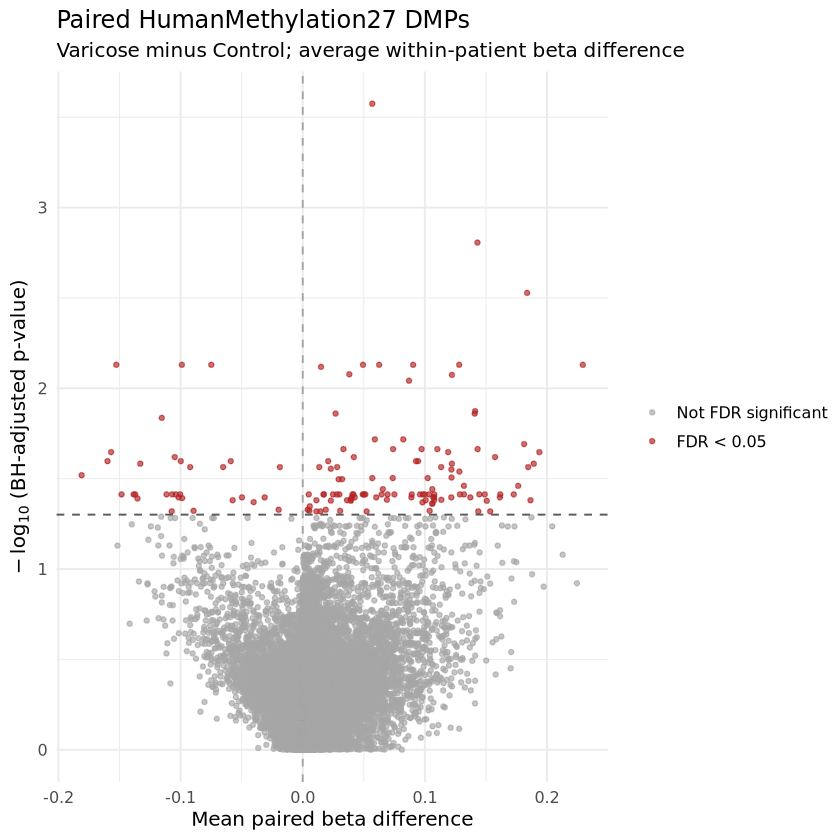

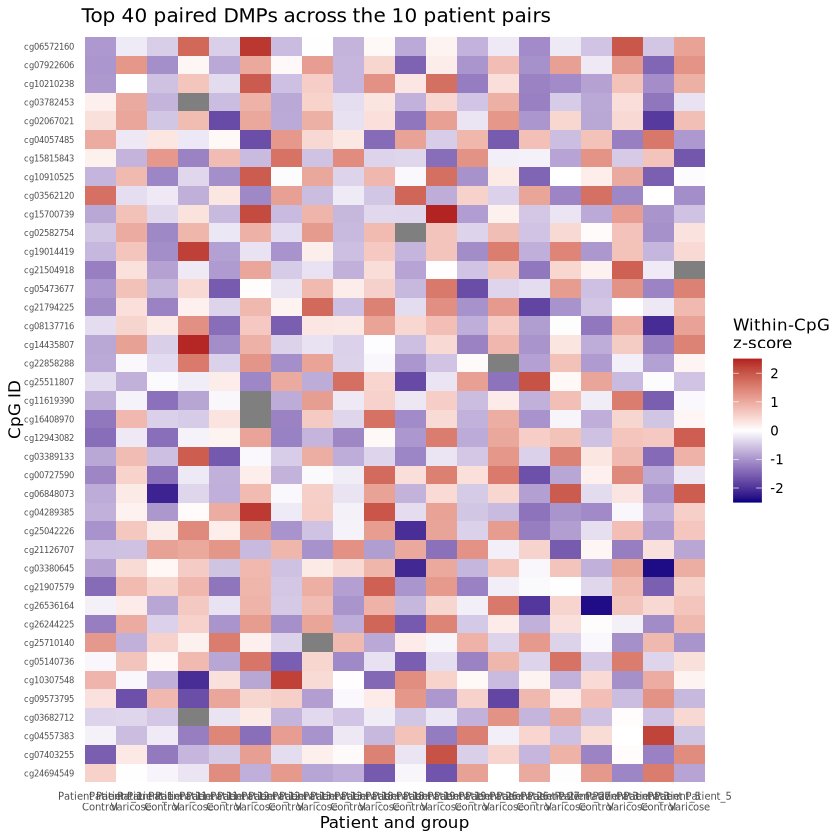

In [11]:
suppressPackageStartupMessages({
  library(IlluminaHumanMethylation27kanno.ilmn12.hg19)
  library(ggplot2)
})

anno27_hg19 <- as.data.frame(
  minfi::getAnnotation(IlluminaHumanMethylation27kanno.ilmn12.hg19)
)
if (nrow(anno27_hg19) != 27578L || anyDuplicated(anno27_hg19$Name)) {
  stop("The installed HumanMethylation27 annotation did not return 27,578 unique CpG IDs.")
}
if (anyNA(anno27_hg19$chr) || anyNA(anno27_hg19$pos)) {
  stop("The HumanMethylation27 hg19 annotation contains missing chromosome positions.")
}

dmp_anno_rows <- match(dmp_results$IlmnID, anno27_hg19$Name)
if (anyNA(dmp_anno_rows)) stop("At least one tested DMP is missing from the 27K annotation.")
dmp_annotated <- as.data.frame(dmp_results)
dmp_annotated$Chr_hg19 <- as.character(anno27_hg19$chr[dmp_anno_rows])
dmp_annotated$MapInfo_hg19 <- as.integer(anno27_hg19$pos[dmp_anno_rows])
dmp_annotated$GenomeBuild_hg19 <- "hg19"
dmp_annotated$Gene_ID_hg19 <- sub(
  "^GeneID:", "", as.character(anno27_hg19$Gene_ID[dmp_anno_rows])
)
dmp_annotated$Symbol_hg19 <- as.character(anno27_hg19$Symbol[dmp_anno_rows])
dmp_annotated$Island_hg19 <- as.character(anno27_hg19$CPG_ISLAND[dmp_anno_rows])
dmp_annotated$Distance_to_TSS_hg19 <- as.integer(anno27_hg19$Distance_to_TSS[dmp_anno_rows])
write.csv(
  dmp_annotated,
  file.path(work_dir, "GSE68319_paired_DMP_annotated_hg19.csv"),
  row.names = FALSE
)
cat("DMPs with a 27K hg19 annotation:", nrow(dmp_annotated), "of", nrow(dmp_results), "\n")

volcano_plot <- ggplot2::ggplot(
  dmp_annotated,
  ggplot2::aes(x = Mean_Paired_Delta_Beta,
               y = -log10(pmax(adj.P.Val, .Machine$double.xmin)),
               color = FDR_Significant)
) +
  ggplot2::geom_point(alpha = 0.65, size = 1.1) +
  ggplot2::geom_hline(yintercept = -log10(0.05), linetype = 2, color = "grey35") +
  ggplot2::geom_vline(xintercept = 0, linetype = 2, color = "grey65") +
  ggplot2::scale_color_manual(
    values = c(`FALSE` = "grey65", `TRUE` = "firebrick"),
    breaks = c(FALSE, TRUE),
    labels = c("Not FDR significant", "FDR < 0.05"),
    name = NULL
  ) +
  ggplot2::labs(
    title = "Paired HumanMethylation27 DMPs",
    subtitle = "Varicose minus Control; average within-patient beta difference",
    x = "Mean paired beta difference",
    y = expression(-log[10] * " (BH-adjusted p-value)")
  ) +
  ggplot2::theme_minimal(base_size = 12)
ggplot2::ggsave(
  file.path(work_dir, "GSE68319_paired_DMP_volcano.png"),
  volcano_plot, width = 8, height = 6, dpi = 300, bg = "white"
)
print(volcano_plot)

top_probe_ids <- head(
  dmp_annotated$IlmnID[order(dmp_annotated$adj.P.Val, dmp_annotated$P.Value)],
  min(40L, nrow(dmp_annotated))
)
heat_meta <- as.data.frame(myLoad$pd[colnames(myLoad$beta), , drop = FALSE])
sample_order <- order(
  as.character(heat_meta$Subject_ID),
  factor(heat_meta$Sample_Group, levels = c("Control", "Varicose"))
)
ordered_samples <- rownames(heat_meta)[sample_order]
beta_top <- myLoad$beta[top_probe_ids, ordered_samples, drop = FALSE]
beta_z <- t(scale(t(beta_top)))
beta_z[!is.finite(beta_z)] <- 0
heat_data <- as.data.frame(as.table(beta_z), stringsAsFactors = FALSE)
names(heat_data) <- c("CpG_ID", "Sample", "Beta_Z")
heat_data$CpG_ID <- factor(heat_data$CpG_ID, levels = rev(top_probe_ids))
heat_data$Sample <- factor(heat_data$Sample, levels = ordered_samples)
sample_labels <- setNames(
  paste0("Patient ", heat_meta[ordered_samples, "Subject_ID"],
         "\n", heat_meta[ordered_samples, "Sample_Group"]),
  ordered_samples
)
heatmap_plot <- ggplot2::ggplot(
  heat_data, ggplot2::aes(x = Sample, y = CpG_ID, fill = Beta_Z)
) +
  ggplot2::geom_tile() +
  ggplot2::scale_x_discrete(labels = sample_labels) +
  ggplot2::scale_fill_gradient2(
    low = "navy", mid = "white", high = "firebrick",
    midpoint = 0, limits = c(-2.5, 2.5), name = "Within-CpG\nz-score"
  ) +
  ggplot2::labs(
    title = "Top 40 paired DMPs across the 10 patient pairs",
    x = "Patient and group", y = "CpG ID"
  ) +
  ggplot2::theme_minimal(base_size = 10) +
  ggplot2::theme(
    axis.text.x = ggplot2::element_text(size = 6),
    axis.text.y = ggplot2::element_text(size = 5),
    panel.grid = ggplot2::element_blank()
  )
ggplot2::ggsave(
  file.path(work_dir, "GSE68319_top40_DMP_beta_heatmap.png"),
  heatmap_plot, width = 12, height = 10, dpi = 300, bg = "white"
)
print(heatmap_plot)

## Step 10 — call differentially methylated regions (DMRs)

The ChAMP vignette next groups nearby significant CpGs into regions with DMRcate. DMRcate's regular `cpg.annotate()` helper is documented for 450K/EPIC array types, so it cannot be told that this is 27K. Instead, this notebook builds the DMRcate `CpGannotated` object directly, using the same fields documented by DMRcate: per-CpG t-statistic, raw p-value, beta difference, individual-CpG FDR, significance flag, and beta matrix. The sites are placed using the 27K hg19 annotation above.

Only chromosomes 1–22, X, and Y are used for region calling. DMRcate uses a 1,000 bp smoothing window (`lambda=1000`) and the vignette-style `C=2`. The region-level results are saved separately from the individual-CpG DMPs.

In [12]:
suppressPackageStartupMessages({
  library(DMRcate)
  library(GenomicRanges)
  library(IRanges)
})

dmr_anno_rows <- match(dmp_results$IlmnID, anno27_hg19$Name)
canonical_chromosomes <- c(paste0("chr", 1:22), "chrX", "chrY")
keep_dmr_cpg <- anno27_hg19$chr[dmr_anno_rows] %in% canonical_chromosomes &
  !is.na(anno27_hg19$pos[dmr_anno_rows])
dmr_dmp <- dmp_results[keep_dmr_cpg, , drop = FALSE]
dmr_anno <- anno27_hg19[dmr_anno_rows[keep_dmr_cpg], , drop = FALSE]
if (nrow(dmr_dmp) < 2L) stop("Fewer than two tested CpGs have canonical hg19 coordinates.")

dmr_gr <- GenomicRanges::GRanges(
  seqnames = dmr_anno$chr,
  ranges = IRanges::IRanges(start = as.integer(dmr_anno$pos), width = 1L),
  stat = as.numeric(dmr_dmp$t),
  rawpval = as.numeric(dmr_dmp$P.Value),
  diff = as.numeric(dmr_dmp$Mean_Paired_Delta_Beta),
  ind.fdr = as.numeric(dmr_dmp$adj.P.Val),
  is.sig = dmr_dmp$adj.P.Val < 0.05
)
names(dmr_gr) <- dmr_dmp$IlmnID
dmr_beta <- myLoad$beta[dmr_dmp$IlmnID, , drop = FALSE]
if (!identical(rownames(dmr_beta), names(dmr_gr))) {
  stop("The DMRcate beta matrix rows and genomic ranges are not in the same order.")
}
dmrcate_input <- methods::new("CpGannotated", ranges = dmr_gr, betas = dmr_beta)

dmrcate_no_region_message <- NULL
dmrcate_results <- tryCatch(
  DMRcate::dmrcate(dmrcate_input, lambda = 1000, C = 2, pcutoff = "fdr"),
  error = function(e) {
    if (grepl("no sign.?ficant (regions|CpGs)", conditionMessage(e), ignore.case = TRUE)) {
      dmrcate_no_region_message <<- conditionMessage(e)
      return(NULL)
    }
    stop(e)
  }
)
if (is.null(dmrcate_results)) {
  message("DMRcate did not identify regions at this threshold: ", dmrcate_no_region_message)
  dmr_ranges_hg19 <- GenomicRanges::GRanges()
} else {
  dmr_ranges_hg19 <- DMRcate::extractRanges(dmrcate_results, genome = "hg19")
}
dmr_table <- as.data.frame(dmr_ranges_hg19)
write.csv(
  dmr_table,
  file.path(work_dir, "GSE68319_DMRcate_regions_hg19.csv"),
  row.names = FALSE
)
saveRDS(
  dmr_ranges_hg19,
  file.path(work_dir, "GSE68319_DMRcate_regions_hg19.rds")
)
cat("Tested CpGs supplied to DMRcate:", nrow(dmr_dmp), "\n")
cat("FDR-significant regions found:", nrow(dmr_table), "\n")
if (nrow(dmr_table)) print(utils::head(dmr_table, 10))

Fitting chr19...



Fitting chr6...



Fitting chr9...



Fitting chr4...



Fitting chr8...



Fitting chr12...



... (21 outputs left out)

loading from cache



Tested CpGs supplied to DMRcate: 26640 


FDR-significant regions found: 36 


   seqnames     start       end width strand no.cpgs min_smoothed_fdr
1      chr9  21995288  21996228   941      *       6     2.369742e-29
2     chr11   2886898   2887741   844      *       5     1.126373e-17
3      chr5 150379974 150380724   751      *       5     1.489021e-17
4      chr4   4913811   4915331  1521      *       6     7.562281e-15
5     chr12   8706575   8707161   587      *       2     3.984164e-14
6     chr19  54350044  54350725   682      *       2     1.619334e-13
7     chr15  72005833  72006360   528      *       2     1.751555e-13
8      chr2 113752640 113753041   402      *       2     2.105529e-12
9     chr12  52713651  52713967   317      *       3     7.513684e-12
10    chr12  79634880  79635143   264      *       2     1.850053e-11
       Stouffer        HMFDR       Fisher     maxdiff    meandiff
1  1.521862e-14 2.573307e-05 1.810951e-13  0.18370351  0.12779520
2  7.019796e-09 9.422288e-05 5.094306e-09  0.14079908  0.09364425
3  7.019796e-09 7.111847e-05 5.0

## Step 11 — GO Biological Process enrichment with 27K probe-bias correction

The ChAMP vignette includes gene-set enrichment after DMP/DMR analysis. Its standard `champ.GSEA()` and `missMethyl::gometh()` array modes are designed around 450K/EPIC, so this 27K analysis uses `goseq` with a custom 27K-specific mapping. Each CpG's 27K `Gene_ID` is converted to an Entrez ID. The background includes only genes represented by probes that passed the detection filter and were tested by limma. One gene list contains genes with at least one BH FDR < 0.05 DMP; the other contains genes touched by the DMRcate regions.

Genes with more 27K CpGs have more chances to show a significant CpG. `goseq` is therefore given each gene's number of tested array CpGs as its bias value. The Wallenius test evaluates GO Biological Process terms with this probe-count adjustment. This is an exploratory gene-set summary, not a separate gene-level differential-methylation test or a ranked-list GSEA.

In [13]:
suppressPackageStartupMessages({
  library(goseq)
  library(org.Hs.eg.db)
  library(AnnotationDbi)
  library(GO.db)
})

gene_id_fields <- as.character(anno27_hg19$Gene_ID)
gene_id_tokens <- regmatches(
  gene_id_fields,
  gregexpr("GeneID:[0-9]+", gene_id_fields, perl = TRUE)
)
probe_gene_map <- unique(data.frame(
  CpG_ID = rep(anno27_hg19$Name, lengths(gene_id_tokens)),
  EntrezID = sub("^GeneID:", "", unlist(gene_id_tokens, use.names = FALSE)),
  stringsAsFactors = FALSE
))
tested_probe_gene <- probe_gene_map[
  probe_gene_map$CpG_ID %in% dmp_results$IlmnID,
  , drop = FALSE
]
if (!nrow(tested_probe_gene)) stop("No tested 27K probes could be mapped to Entrez genes.")

probe_counts <- table(tested_probe_gene$EntrezID)
gene_universe <- names(probe_counts)
sig_dmp_ids <- dmp_results$IlmnID[dmp_results$adj.P.Val < 0.05]
sig_gene_ids <- unique(tested_probe_gene$EntrezID[
  tested_probe_gene$CpG_ID %in% sig_dmp_ids
])

# Mark genes that have one or more tested 27K probes inside a called DMR.
tested_anno_rows <- match(dmp_results$IlmnID, anno27_hg19$Name)
tested_cpg_ranges <- GenomicRanges::GRanges(
  seqnames = anno27_hg19$chr[tested_anno_rows],
  ranges = IRanges::IRanges(
    start = as.integer(anno27_hg19$pos[tested_anno_rows]), width = 1L
  )
)
names(tested_cpg_ranges) <- dmp_results$IlmnID
dmr_probe_ids <- names(tested_cpg_ranges)[
  unique(S4Vectors::queryHits(
    GenomicRanges::findOverlaps(tested_cpg_ranges, dmr_ranges_hg19)
  ))
]
dmr_gene_ids <- unique(tested_probe_gene$EntrezID[
  tested_probe_gene$CpG_ID %in% dmr_probe_ids
])

sig_cpg_counts <- table(factor(
  tested_probe_gene$EntrezID[tested_probe_gene$CpG_ID %in% sig_dmp_ids],
  levels = gene_universe
))
dmr_cpg_counts <- table(factor(
  tested_probe_gene$EntrezID[tested_probe_gene$CpG_ID %in% dmr_probe_ids],
  levels = gene_universe
))
gene_summary <- data.frame(
  EntrezID = gene_universe,
  N_tested_27K_CpGs = as.numeric(probe_counts[gene_universe]),
  N_FDR_lt_0.05_CpGs = as.numeric(sig_cpg_counts),
  N_DMR_overlap_CpGs = as.numeric(dmr_cpg_counts),
  stringsAsFactors = FALSE
)
gene_summary$Has_FDR_significant_CpG <- gene_summary$N_FDR_lt_0.05_CpGs > 0
gene_summary$Has_DMR_overlap <- gene_summary$N_DMR_overlap_CpGs > 0
write.csv(
  gene_summary,
  file.path(work_dir, "GSE68319_27k_gene_level_CpG_summary.csv"),
  row.names = FALSE
)

go_map <- AnnotationDbi::select(
  org.Hs.eg.db,
  keys = gene_universe,
  keytype = "ENTREZID",
  columns = c("GO", "ONTOLOGY")
)
go_bp <- unique(go_map[
  !is.na(go_map$GO) & go_map$ONTOLOGY == "BP",
  c("ENTREZID", "GO"), drop = FALSE
])
gene2cat_bp <- data.frame(
  gene = as.character(go_bp$ENTREZID),
  category = as.character(go_bp$GO),
  stringsAsFactors = FALSE
)
if (!nrow(gene2cat_bp)) stop("No GO Biological Process annotations matched the tested genes.")

probe_bias <- stats::setNames(as.numeric(probe_counts[gene_universe]), gene_universe)
gene_sets <- list(
  DMP_FDR_lt_0.05 = sig_gene_ids,
  DMR_overlapping_probes = dmr_gene_ids
)

run_bias_adjusted_go <- function(selected_genes, analysis_set) {
  de_vector <- stats::setNames(
    as.integer(gene_universe %in% selected_genes), gene_universe
  )
  pwf <- goseq::nullp(
    DEgenes = de_vector,
    genome = "hg19",
    id = "entrezgene",
    bias.data = probe_bias,
    plot.fit = FALSE
  )
  result <- goseq::goseq(
    pwf = pwf,
    genome = "hg19",
    id = "entrezgene",
    gene2cat = gene2cat_bp,
    test.cats = "GO:BP",
    method = "Wallenius",
    use_genes_without_cat = FALSE
  )
  if (nrow(result)) {
    result$BH_FDR <- p.adjust(result$over_represented_pvalue, method = "BH")
    if (!"term" %in% names(result)) {
      term_map <- AnnotationDbi::select(
        GO.db,
        keys = unique(result$category),
        keytype = "GOID",
        columns = "TERM"
      )
      names(term_map)[names(term_map) == "GOID"] <- "category"
      names(term_map)[names(term_map) == "TERM"] <- "term"
      result <- merge(result, term_map, by = "category", all.x = TRUE, sort = FALSE)
    }
  }
  result$Analysis_Set <- analysis_set
  list(pwf = pwf, results = result)
}

goseq_runs <- lapply(names(gene_sets), function(set_name) {
  run_bias_adjusted_go(gene_sets[[set_name]], set_name)
})
names(goseq_runs) <- names(gene_sets)
go_bp_results <- do.call(rbind, lapply(goseq_runs, `[[`, "results"))
if (nrow(go_bp_results)) {
  go_bp_results <- go_bp_results[
    order(go_bp_results$Analysis_Set, go_bp_results$BH_FDR,
          go_bp_results$over_represented_pvalue),
    , drop = FALSE
  ]
}
write.csv(
  go_bp_results,
  file.path(work_dir, "GSE68319_27k_GO_BP_goseq.csv"),
  row.names = FALSE
)

grDevices::png(
  file.path(work_dir, "GSE68319_27k_GOseq_probe_bias_fit.png"),
  width = 1400, height = 950, res = 150
)
goseq::plotPWF(goseq_runs[["DMP_FDR_lt_0.05"]][["pwf"]])
grDevices::dev.off()

cat("Genes represented by tested 27K CpGs:", length(gene_universe), "\n")
cat("Genes with at least one FDR-significant CpG:", length(sig_gene_ids), "\n")
cat("Genes with at least one CpG in a called DMR:", length(dmr_gene_ids), "\n")
for (set_name in names(goseq_runs)) {
  result <- goseq_runs[[set_name]][["results"]]
  cat(set_name, "GO BP terms:", nrow(result),
      "terms at BH FDR < 0.05:", sum(result$BH_FDR < 0.05, na.rm = TRUE), "\n")
  if (nrow(result)) {
    print(utils::head(result[order(result$BH_FDR, result$over_represented_pvalue), ], 10))
  }
}

'select()' returned 1:many mapping between keys and columns



Warning message in pcls(G):
"initial point very close to some inequality constraints"


Using manually entered categories.



For 1257 genes, we could not find any categories. These genes will be excluded.



To force their use, please run with use_genes_without_cat=TRUE (see documentation).



This was the default behavior for version 1.15.1 and earlier.



... (10 outputs left out)

Genes represented by tested 27K CpGs: 14111 


Genes with at least one FDR-significant CpG: 131 


Genes with at least one CpG in a called DMR: 37 


DMP_FDR_lt_0.05 GO BP terms: 11796 terms at BH FDR < 0.05: 0 
        category over_represented_pvalue under_represented_pvalue numDEInCat
1687  GO:0007267            0.0003508191                0.9999315          9
11580 GO:2000611            0.0004188988                0.9999977          2
2558  GO:0015721            0.0005907535                0.9999796          3
2355  GO:0010880            0.0007724879                0.9999704          3
4117  GO:0033363            0.0008894685                0.9999916          2
7209  GO:0060415            0.0016087176                0.9999764          2
5100  GO:0042693            0.0016781222                0.9999762          2
1644  GO:0007189            0.0017789129                0.9997069          6
11780 GO:2001256            0.0031994694                0.9999273          2
907   GO:0003281            0.0039915345                0.9997192          3
      numInCat
1687       210
11580        4
2558        19
2355        21
4117         5
7

## Interpretation and limits

The reported coefficient is **Varicose minus Control** on the M-value scale. `Mean_Paired_Delta_Beta` is the average within-patient beta difference (positive means higher beta in varicose samples). BH FDR is calculated across all probes that pass the detection-p filter.

ChAMP's released `champ.DMP` documents support for 450K/EPIC, not 27K. The notebook therefore implements a clearly labeled 27K paired DMP wrapper with limma, instead of pretending 27K is a 450K/EPIC array. minfi documents partial 27K support and `preprocessIllumina()` as GenomeStudio-like preprocessing. This small matched cohort is suitable for a reproducible practice analysis, but DMPs should not be treated as clinically validated findings.

The additional annotation, plots, DMRs, gene summary, and GO results are also saved in `~/GSE68319/`. Review the sample-QC table and density plot before interpreting any downstream result.

The DMR step uses DMRcate's documented `CpGannotated` input structure because its standard array helper is set up for 450K/EPIC; the custom object is built with 27K IDs and hg19 coordinates. The GO step is a 27K-aware GOseq over-representation analysis, not stock `champ.GSEA()`: it uses tested genes as the background and accounts for how many tested CpGs map to each gene. The original GPL8490 build-36 coordinates remain in the DMP table; the added region coordinates are from the HumanMethylation27 hg19 annotation package.

References: [GSE68319 GEO record](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE68319), [ChAMP Bioconductor documentation](https://bioconductor.org/packages/release/bioc/html/ChAMP.html), [minfi User Guide](https://bioconductor.org/packages/release/bioc/vignettes/minfi/inst/doc/minfi.html).
